## Read Data Set

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
dsrumah = pd.read_excel('DatasetHargaRumah.xlsx')

### Data Rumah

In [26]:
dsrumah

,luas_m2,kamar,kamar_mandi,usia_rumah,jarak_kota_km,harga_juta
0,205,5,3,3,19.0,1386
1,178,4,2,10,4.4,1112
2,68,3,2,7,7.4,780
3,157,5,4,23,3.2,1163
4,57,2,2,1,7.4,712
...,...,...,...,...,...,...
1495,158,3,1,2,15.5,1081
1496,70,3,2,21,16.4,558
1497,51,2,2,2,4.1,497
1498,231,6,4,24,19.8,1472


In [27]:
dsrumah.describe()

,luas_m2,kamar,kamar_mandi,usia_rumah,jarak_kota_km,harga_juta
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,142.432667,4.054667,2.650667,15.132000,10.590400,1041.113333
std,62.408488,1.293881,0.977720,9.002107,5.489511,370.942304
min,36.000000,1.000000,1.000000,0.000000,0.800000,180.000000
25%,89.000000,3.000000,2.000000,7.000000,5.800000,719.000000
50%,142.000000,4.000000,3.000000,15.000000,10.700000,1032.500000
75%,197.000000,5.000000,3.000000,23.000000,15.600000,1355.500000
max,250.000000,6.000000,4.000000,30.000000,20.000000,1883.000000


In [28]:
dsrumah.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   luas_m2        1500 non-null   int64  
 1   kamar          1500 non-null   int64  
 2   kamar_mandi    1500 non-null   int64  
 3   usia_rumah     1500 non-null   int64  
 4   jarak_kota_km  1500 non-null   float64
 5   harga_juta     1500 non-null   int64  
dtypes: float64(1), int64(5)
memory usage: 70.4 KB


## Praproses

In [29]:
dsrumah[dsrumah.duplicated()]

,luas_m2,kamar,kamar_mandi,usia_rumah,jarak_kota_km,harga_juta


In [30]:
dsrumah.shape

(1500, 6)

### 1500 baris, 5 fitur, 1 target, tanpa null dan tanpa duplikat.

In [31]:
#Korelasi antar variabel
dsrumah.corr()

,luas_m2,kamar,kamar_mandi,usia_rumah,jarak_kota_km,harga_juta
luas_m2,1.000000,0.850727,0.652982,0.011346,0.024780,0.943280
kamar,0.850727,1.000000,0.765508,0.006310,0.011007,0.884665
kamar_mandi,0.652982,0.765508,1.000000,0.012216,0.007180,0.743424
usia_rumah,0.011346,0.006310,0.012216,1.000000,-0.015464,-0.112932
jarak_kota_km,0.024780,0.011007,0.007180,-0.015464,1.000000,-0.027521
harga_juta,0.943280,0.884665,0.743424,-0.112932,-0.027521,1.000000


## Visualisasi Matriks Korelasi

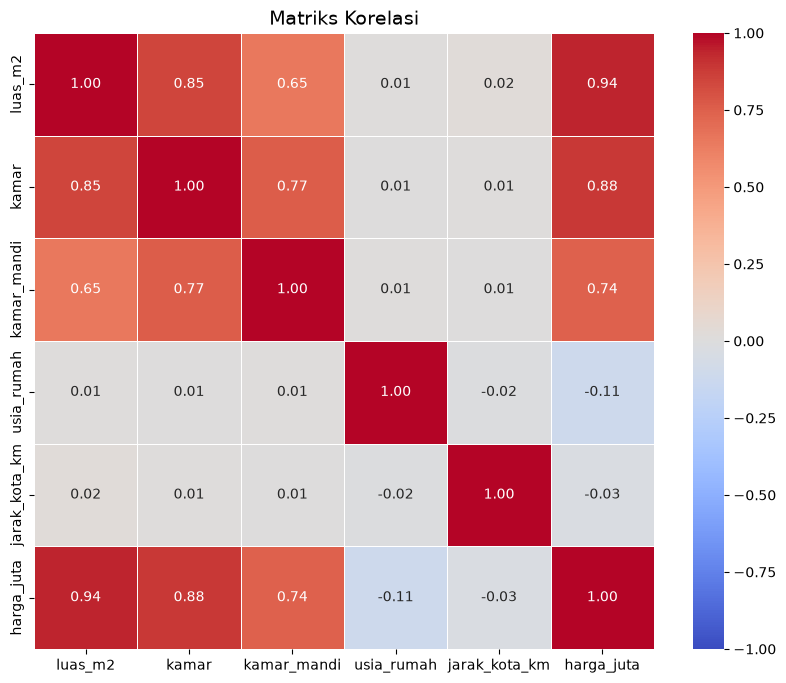

In [32]:
plt.figure(figsize=(10, 8))
sns.heatmap(dsrumah.corr(numeric_only=True), 
            annot=True, 
            cmap='coolwarm', 
            fmt='.2f', 
            vmin=-1, 
            vmax=1, 
            linewidths=0.5)
plt.title('Matriks Korelasi', fontsize=14)
plt.show()

### Interpretasi Matriks Korelasi

Nilai korelasi berkisar -1 sampai +1. Positif berarti naik bersama, negatif berarti berlawanan arah, mendekati 0 berarti hampir tidak ada hubungan linier.

Korelasi setiap fitur terhadap `harga_juta`:

| Fitur | Korelasi | Penjelasan |
|---|---|---|
| `luas_m2` | +0.94 | Sangat kuat. Makin luas, makin mahal |
| `kamar` | +0.88 | Kuat. Rumah dengan kamar banyak umumnya lebih luas dan mahal |
| `kamar_mandi` | +0.74 | Cukup kuat |
| `usia_rumah` | -0.11 | Lemah. Makin tua rumah, harga sedikit turun |
| `jarak_kota_km` | -0.03 | Hampir tidak ada pengaruh pada dataset ini |

**Catatan multikolinearitas:** antar fitur juga berkorelasi (`luas_m2` dengan `kamar` = 0.85, `kamar` dengan `kamar_mandi` = 0.77). Informasi fitur-fitur ini saling tumpang tindih, sehingga pengaruh masing-masing sulit dipisahkan. Prediksi model tetap bagus, tetapi koefisien regresinya perlu ditafsirkan dengan hati-hati.

Korelasi berbeda dengan koefisien regresi. Korelasi menunjukkan kekuatan hubungan dua variabel, sedangkan koefisien menunjukkan perubahan harga untuk setiap kenaikan 1 satuan fitur (dengan fitur lain dianggap tetap). Korelasi juga bukan bukti sebab-akibat.

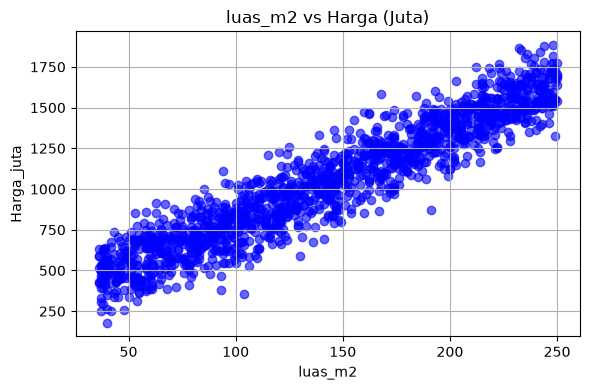

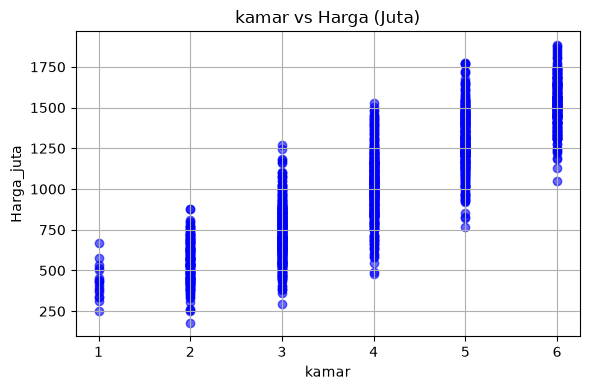

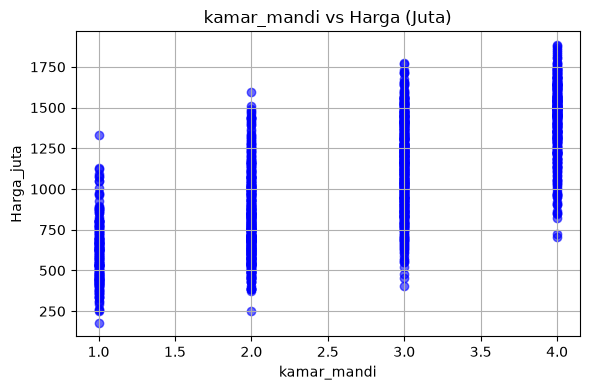

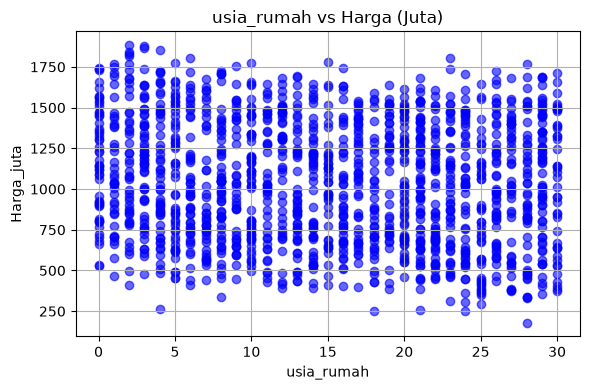

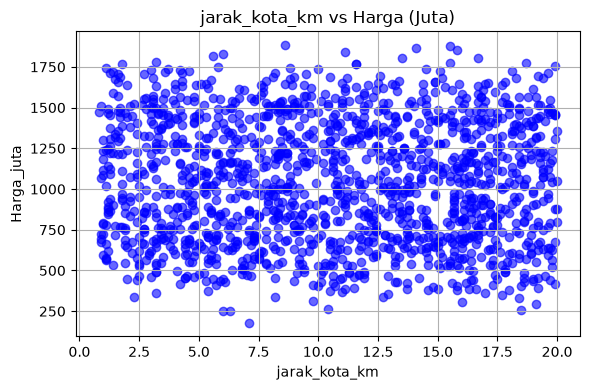

In [33]:
# visualisasi hubungan antara setiap fitur dan target
for kolom in dsrumah.iloc[:, :5]:
    plt.figure(figsize=(6, 4))
    plt.scatter(dsrumah[kolom], dsrumah.iloc[:, 5], alpha=0.6, color='b')
    plt.title(f"{kolom} vs Harga (Juta)")
    plt.xlabel(kolom)
    plt.ylabel("Harga_juta")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## Variabel

In [34]:
x = dsrumah.iloc[:, :5].values
y = dsrumah.iloc[:, 5].values

Variabel **X** adalah **variabel independen (fitur)**, yaitu variabel yang mempengaruhi variabel lain tetapi tidak dipengaruhi variabel lain dalam dataset ini. Fitur berada di kolom indeks 0 - 4: `luas_m2`, `kamar`, `kamar_mandi`, `usia_rumah`, `jarak_kota_km`.

Variabel **y** adalah **variabel dependen (target)**, yaitu `harga_juta` di kolom indeks 5.

`harga_juta` dijadikan y karena itulah yang ingin diprediksi dan nilainya kontinu, sehingga ini adalah masalah **regresi**. Lima kolom lainnya dijadikan X karena merupakan karakteristik rumah yang sudah diketahui sebelum harga ditentukan.

## Modeling

In [35]:
#Split Test
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

25% data untu data uji x_test dan y_test 75% sisanya digunakan untuk training x_train dan y_train.

In [ ]:
#Training MODEL
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [ ]:
model.fit(x_train, y_train)

# Simpan model SETELAH dilatih
import joblib
joblib.dump(model, 'model_rumah.pkl')

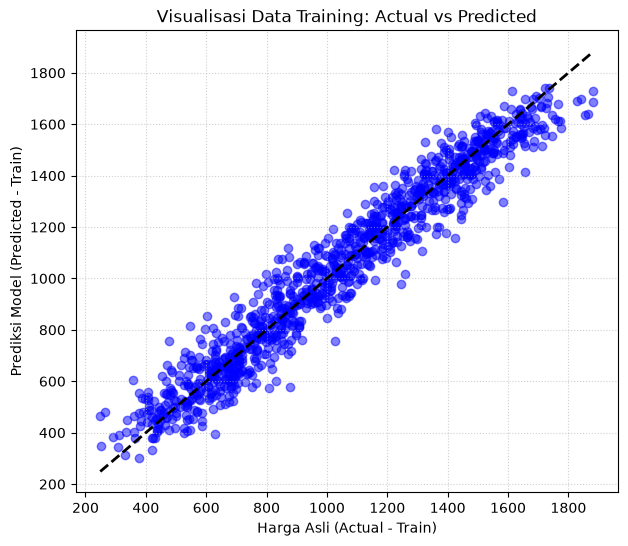

In [38]:
y_pred_train = model.predict(x_train)

# Membuat grafik terpisah untuk Training
plt.figure(figsize=(7, 6))
plt.scatter(y_train, y_pred_train, color='blue', alpha=0.5)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', lw=2)
plt.xlabel('Harga Asli (Actual - Train)')
plt.ylabel('Prediksi Model (Predicted - Train)')
plt.title('Visualisasi Data Training: Actual vs Predicted')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## Prediksi

In [39]:
y_predik = model.predict(x_test)

In [40]:
y_predik

array([1661.29795161, 1126.99649264, 1140.86308773,  927.16571314,
       1128.48307737,  757.66394261,  536.91760087,  859.39384036,
        936.09033604,  537.1102926 , 1610.43739873, 1186.88936071,
        789.57821482, 1614.456101  ,  504.40064338, 1172.64419348,
        440.16703479,  519.86676925, 1343.38512996,  614.49210156,
       1457.92105168,  564.33661511,  824.39265306,  654.97239396,
       1134.24323116,  692.02235523, 1128.7458532 ,  512.74728132,
        553.458975  , 1357.75573529,  784.19993427, 1108.78314636,
       1558.65170908,  969.43490215,  706.8190504 ,  826.80152065,
       1538.25029902,  614.06935041, 1046.45838417, 1094.17878352,
       1086.58936353,  766.66063469,  660.76730325,  939.79797215,
        983.87164117, 1556.52930578, 1496.52788833, 1651.57376416,
       1548.44503849,  869.63324363, 1098.76654373, 1213.57914685,
       1581.75734255,  833.70378758,  679.28183784,  986.01387748,
       1283.41804761, 1310.00234376,  616.20863085, 1592.18912

### Evaluasi

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_predik)
mse = mean_squared_error(y_test, y_predik)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_predik)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2 Score): {r2:.2f}")

Mean Absolute Error (MAE): 72.65
Mean Squared Error (MSE): 8242.16
Root Mean Squared Error (RMSE): 90.79
R-squared (R2 Score): 0.94


### Interpretasi Metrik Evaluasi

**R² Score = 0.94 (94%)**
- Model Linear Regression mampu menjelaskan sekitar 94% variasi harga rumah. Ini mengindikasikan bahwa hubungan antara fitur dan harga pada dataset ini **mendekati linier**.

**MAE = 72.65**
- Rata-rata tebakan model meleset sekitar **72.65 juta rupiah** dari harga sebenarnya. Dibandingkan harga rata-rata sekitar 1.041 juta, ini sekitar 7%.

**MSE = 8242.16**
- Rata-rata kuadrat error (satuannya juta kuadrat, sehingga lebih sulit dibayangkan).

**RMSE = 90.79**
- Error rata-rata dalam satuan juta rupiah, dengan penekanan lebih pada error besar. Nilainya sedikit lebih tinggi dari MAE (90.79 vs 72.65), artinya ada beberapa rumah yang tebakannya meleset lebih jauh dari rata-rata. Karena selisihnya tidak terlalu besar, error model cenderung merata.

### Prediksi Data Baru

In [42]:
databaru = [[107, 2, 1, 5, 9.1]]
prediksibaru = model.predict(databaru)
print("Prediksi: ", prediksibaru)

Prediksi:  [757.09184051]


### Visualisasi nilai asli vs hasil prediksi.

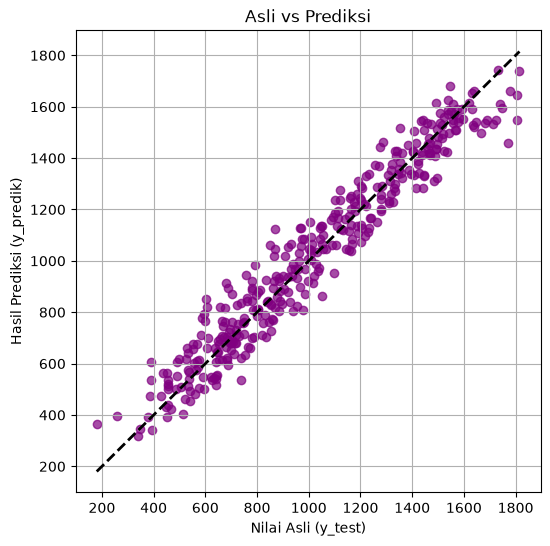

In [43]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_predik, alpha=0.7, color='purple')
plt.xlabel("Nilai Asli (y_test)")
plt.ylabel("Hasil Prediksi (y_predik)")
plt.title("Asli vs Prediksi")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.grid(True)
plt.show()

## Interpretasi Grafik Asli vs Prediksi

- Titik-titik ungu berkumpul **rapat mengikuti garis diagonal hitam** (garis ideal, prediksi = nilai asli) dari harga rendah (sekitar 200 juta) sampai tinggi (sekitar 1.800 juta). Ini sejalan dengan R² 0.94.
- Sebaran titik cukup merata di sepanjang garis. Tidak terlihat kecenderungan model selalu menebak terlalu tinggi atau terlalu rendah pada rentang harga tertentu, meski ada beberapa titik yang menyimpang lebih jauh (penyebab RMSE lebih besar dari MAE).
- Pola pada data uji yang mirip dengan data latih menandakan model tidak menunjukkan gejala overfitting yang jelas.

## Kesimpulan

1. **Fitur dan target:** 5 fitur (`luas_m2`, `kamar`, `kamar_mandi`, `usia_rumah`, `jarak_kota_km`) digunakan untuk memprediksi target `harga_juta`.
2. **Fitur paling berpengaruh:** `luas_m2` (korelasi 0.94), lalu `kamar` (0.88) dan `kamar_mandi` (0.74). `usia_rumah` berpengaruh kecil (-0.11) dan `jarak_kota_km` hampir tidak berpengaruh (-0.03) pada dataset ini.
3. **Performa model:** Linear Regression menghasilkan R² = 0.94, MAE = 72.65 juta, dan RMSE = 90.79 juta. Rata-rata tebakan meleset sekitar 7% dari harga rata-rata, sehingga model tergolong sangat baik.
4. **Mengapa Linear Regression cocok:** hubungan fitur utama dengan harga mendekati linier, sehingga model garis lurus sudah cukup tanpa perlu algoritma yang lebih kompleks.
5. **Keterbatasan:** fitur `luas_m2`, `kamar`, dan `kamar_mandi` saling berkorelasi (multikolinearitas), sehingga pengaruh masing-masing sulit dipisahkan. Dataset juga tidak memuat faktor lain seperti lokasi spesifik atau kondisi bangunan.